# Upper Bounds for American Options: Rogers' Dual Method

This notebook computes an **upper bound** on the price of an American put in the Black-Scholes model, using the dual formulation of Rogers (2002):
$$U_0 = \inf_{M\in\mathcal M} \mathbb E\Big[\max_{0\le t\le T}\big(e^{-rt}\varphi(S_t) - M_t\big)\Big],$$
where $\mathcal M$ is the set of martingales starting at 0. It is based on a lab assignment in stochastic finance at Ensimag (Grenoble INP).

### Why any martingale gives an upper bound

For any martingale $M$ with $M_0 = 0$ and any stopping time $\tau\le T$, optional stopping gives $\mathbb E[M_\tau]=0$, so
$$\mathbb E[e^{-r\tau}\varphi(S_\tau)] = \mathbb E[e^{-r\tau}\varphi(S_\tau) - M_\tau] \le \mathbb E\big[\max_t (e^{-rt}\varphi(S_t) - M_t)\big].$$
Taking the sup over $\tau$ on the left gives the bound. Equality holds for the martingale part of the Doob-Meyer decomposition of the Snell envelope.

### Martingale family

Following Rogers, we search over the one-parameter family $\lambda M$, with $dM_t = \mathbf 1_{\{t\ge\tau_0\}}\,d\tilde C_t$, where $\tilde C$ is the **discounted** European put price and $\tau_0=\inf\{t: \varphi(S_t)>0\}$.

### Setup

Parameters from Rogers' paper: $T=0.5$, $\sigma=0.4$, $K=S_0=100$, $r=0.06$. In practice we work with the Bermudan option exercisable at the $n+1$ dates $t_k = kT/n$, $k=0,\dots,n$.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.stats import norm

T, sigma, K, S0, r = 0.5, 0.4, 100.0, 100.0, 0.06
SEED = 2026

## 1. Building blocks: payoff, Black-Scholes formulas, simulation

The European put price and delta use
$$d_1(t,x) = \frac{1}{\sigma\sqrt{T-t}}\Big(\log\frac{x}{K} + \big(r+\tfrac{\sigma^2}{2}\big)(T-t)\Big).$$
At $t=T$ they are extended by continuity: $C_T = (K-S_T)^+$ and $\Delta_T = -\mathbf 1_{\{S_T<K\}}$.

Paths are simulated **exactly** at the grid dates: $S_{t_{k+1}} = S_{t_k}\exp\big((r-\tfrac{\sigma^2}{2})\delta + \sigma\sqrt\delta\, G_k\big)$, with $\delta = T/n$ and $G_k\sim\mathcal N(0,1)$ i.i.d.

In [ ]:
def payoff(x):
    return np.maximum(K - x, 0.0)


def bs_put(t, x):
    tau = T - t
    if tau <= 1e-14:
        return payoff(x), -(x < K).astype(float)
    sq = sigma * np.sqrt(tau)
    d1 = (np.log(x / K) + (r + 0.5 * sigma**2) * tau) / sq
    d2 = d1 - sq
    price = -x * norm.cdf(-d1) + K * np.exp(-r * tau) * norm.cdf(-d2)
    delta = -norm.cdf(-d1)
    return price, delta


def simulate_paths(n, M, rng):
    # Paths of S at dates t_k = kT/n, array of shape (M, n+1)
    dt = T / n
    G = rng.standard_normal((M, n))
    log_incr = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * G
    logS = np.concatenate([np.zeros((M, 1)), np.cumsum(log_incr, axis=1)], axis=1)
    return S0 * np.exp(logS)


# Sanity check: Black-Scholes European put vs Monte Carlo
rng = np.random.default_rng(SEED)
S_test = simulate_paths(10, 200_000, rng)
mc = np.exp(-r * T) * payoff(S_test[:, -1])
print(f"European put (BS): {bs_put(0.0, np.array([S0]))[0][0]:.4f}")
print(f"Monte Carlo      : {mc.mean():.4f} ± {1.96 * mc.std() / np.sqrt(len(mc)):.4f}")

European put (BS): 9.6642
Monte Carlo      : 9.6707 ± 0.0568


## 2. The two martingales

For each path we compute:
- $Z_{t_k} = e^{-rt_k}\varphi(S_{t_k})$, the discounted payoff;
- $\tau_0$, the first grid date with $\varphi(S_{t_k})>0$ ($\tau_0=+\infty$ if there is none, in which case $M\equiv 0$);
- the **exact martingale** $M_{t_k} = \tilde C_{t_k\vee\tau_0} - \tilde C_{\tau_0}$, equal to 0 before $\tau_0$ and to $\tilde C_{t_k} - \tilde C_{\tau_0}$ after;
- the **discrete hedging portfolio** $\hat M_{t_k} = \sum_{j<k} \Delta_{t_j}\,\mathbf 1_{\{t_j\ge\tau_0\}}\,(\tilde S_{t_{j+1}} - \tilde S_{t_j})$.

Both are martingales on the grid. $\tilde C$ is a martingale (discounted price of a traded asset under the risk-neutral measure) and $\tau_0$ is a stopping time, so $\tilde C_{t\vee\tau_0}$ is a martingale by optional stopping. $\hat M$ is a discrete stochastic integral: $\Delta_{t_j}\mathbf 1_{\{t_j\ge\tau_0\}}$ is $\mathcal F_{t_j}$-measurable and $\mathbb E[\tilde S_{t_{j+1}}-\tilde S_{t_j}\mid\mathcal F_{t_j}]=0$. It is a true martingale **for any $n$**, so the bound it gives is always valid; only its tightness depends on $n$.

In continuous time, since $S_0=K$, the price drops below $K$ immediately, so $\tau_0=0$ a.s. and $M_t=\tilde C_t-\tilde C_0$. The indicator only matters on the discrete grid.

In [ ]:
def build_sample(n, M, rng):
    # Returns Z (discounted payoff), M_exact and M_hat (discrete hedge), all of shape (M, n+1)
    t = np.linspace(0.0, T, n + 1)
    disc = np.exp(-r * t)
    S = simulate_paths(n, M, rng)
    Z = disc * payoff(S)

    # tau0: index of the first date with positive payoff (n+1 if never)
    hit = Z > 0
    idx0 = np.where(hit.any(axis=1), hit.argmax(axis=1), n + 1)
    after = np.arange(n + 1)[None, :] >= idx0[:, None]  # 1_{t_k >= tau0}

    # Discounted European price and deltas
    Ct = np.empty_like(S)
    Delta = np.empty_like(S)
    for k in range(n + 1):
        p, d = bs_put(t[k], S[:, k])
        Ct[:, k] = disc[k] * p
        Delta[:, k] = d

    # Exact martingale
    rows = np.arange(M)
    C_tau0 = np.where(idx0 <= n, Ct[rows, np.minimum(idx0, n)], 0.0)
    M_exact = np.where(after, Ct - C_tau0[:, None], 0.0)

    # Discrete hedging portfolio
    S_disc = disc * S
    incr = Delta[:, :-1] * after[:, :-1] * np.diff(S_disc, axis=1)
    M_hat = np.concatenate([np.zeros((M, 1)), np.cumsum(incr, axis=1)], axis=1)

    del S, Ct, Delta, S_disc, incr, hit, after
    return Z, M_exact, M_hat


rng = np.random.default_rng(SEED)
Z, Mex, Mh = build_sample(10, 100_000, rng)
print("E[M_T] exact   :", Mex[:, -1].mean().round(4), " (should be ≈ 0)")
print("E[M_T] discrete:", Mh[:, -1].mean().round(4), " (should be ≈ 0)")

E[M_T] exact   : 0.0011  (should be ≈ 0)
E[M_T] discrete: 0.0006  (should be ≈ 0)


## 3. Monte Carlo estimator for a given $\lambda$

$$\hat V_M(\lambda) = \frac1M\sum_{i=1}^M \max_{0\le k\le n}\Big(e^{-rt_k}\varphi(S^{(i)}_{t_k}) - \lambda M^{(i)}_{t_k}\Big)$$
The function also returns the standard error, to build confidence intervals.

In [4]:
def dual_estimator(lam, Z, Mart, return_std=False):
    X = np.max(Z - lam * Mart, axis=1)
    if return_std:
        return X.mean(), X.std(ddof=1) / np.sqrt(len(X))
    return X.mean()


for lam in [0.0, 0.5, 1.0]:
    v, se = dual_estimator(lam, Z, Mex, return_std=True)
    print(f"lambda = {lam:.1f} : {v:.4f}  (std error {se:.4f})")

lambda = 0.0 : 15.3300  (std error 0.0410)
lambda = 0.5 : 12.1419  (std error 0.0273)
lambda = 1.0 : 9.9449  (std error 0.0169)


With $\lambda=0$ we get $\mathbb E[\max_k Z_{t_k}]$, the value for a holder with perfect foresight: a very loose bound. The martingale term penalizes this look-ahead by removing, on average, what is gained by knowing the future.

## 4. Optimizing $\lambda$ with the exact martingale

$\lambda\mapsto\hat V_M(\lambda)$ is an average of maxima of affine functions of $\lambda$, so it is **convex** (and piecewise linear). A bounded 1D search (Brent) is enough, with no spurious local minima.

$\min_\lambda \hat V_M(\lambda)$ is biased **downwards**, since $\mathbb E[\min_\lambda \hat V_M(\lambda)] \le \min_\lambda \mathbb E[\hat V_M(\lambda)]$, so strictly speaking it is not an upper bound. To fix this, $\hat\lambda$ is estimated on a training sample, then $\hat V(\hat\lambda)$ is re-evaluated on an **independent** sample. With $\hat\lambda$ fixed, this estimator is unbiased for $\mathbb E[\max_k(Z_{t_k}-\hat\lambda M_{t_k})]\ge U_0^{\text{berm}}$: a genuine upper bound, with a confidence interval.

In [ ]:
def optimize_lambda(Z, Mart, bounds=(0.0, 3.0)):
    res = minimize_scalar(lambda l: dual_estimator(l, Z, Mart), bounds=bounds,
                          method="bounded", options={"xatol": 1e-4})
    return res.x, res.fun


def dual_upper_bound(n, M, which, seed=SEED):
    rng = np.random.default_rng(seed)
    Z1, Me1, Mh1 = build_sample(n, M, rng)  
    Mart1 = Me1 if which == "exact" else Mh1
    lam, v_in = optimize_lambda(Z1, Mart1)
    del Z1, Me1, Mh1, Mart1
    Z2, Me2, Mh2 = build_sample(n, M, rng)       
    Mart2 = Me2 if which == "exact" else Mh2
    v_out, se = dual_estimator(lam, Z2, Mart2, return_std=True)
    v0 = dual_estimator(0.0, Z2, Mart2)
    return dict(n=n, lam=lam, in_sample=v_in, upper=v_out, se=se, no_mart=v0)


t0 = time.time()
res_exact = dual_upper_bound(10, 100_000, "exact")
print(f"n = 10, M = 1e5, exact martingale  ({time.time()-t0:.1f} s)")
print(f"  lambda*                     = {res_exact['lam']:.4f}")
print(f"  in-sample min               = {res_exact['in_sample']:.4f}")
print(f"  upper bound (out-of-sample) = {res_exact['upper']:.4f}  ± {1.96*res_exact['se']:.4f} (95% CI)")

n = 10, M = 1e5, exact martingale  (0.4 s)
  lambda*                     = 1.0251
  in-sample min               = 9.9317
  upper bound (out-of-sample) = 9.9266  ± 0.0330 (95% CI)


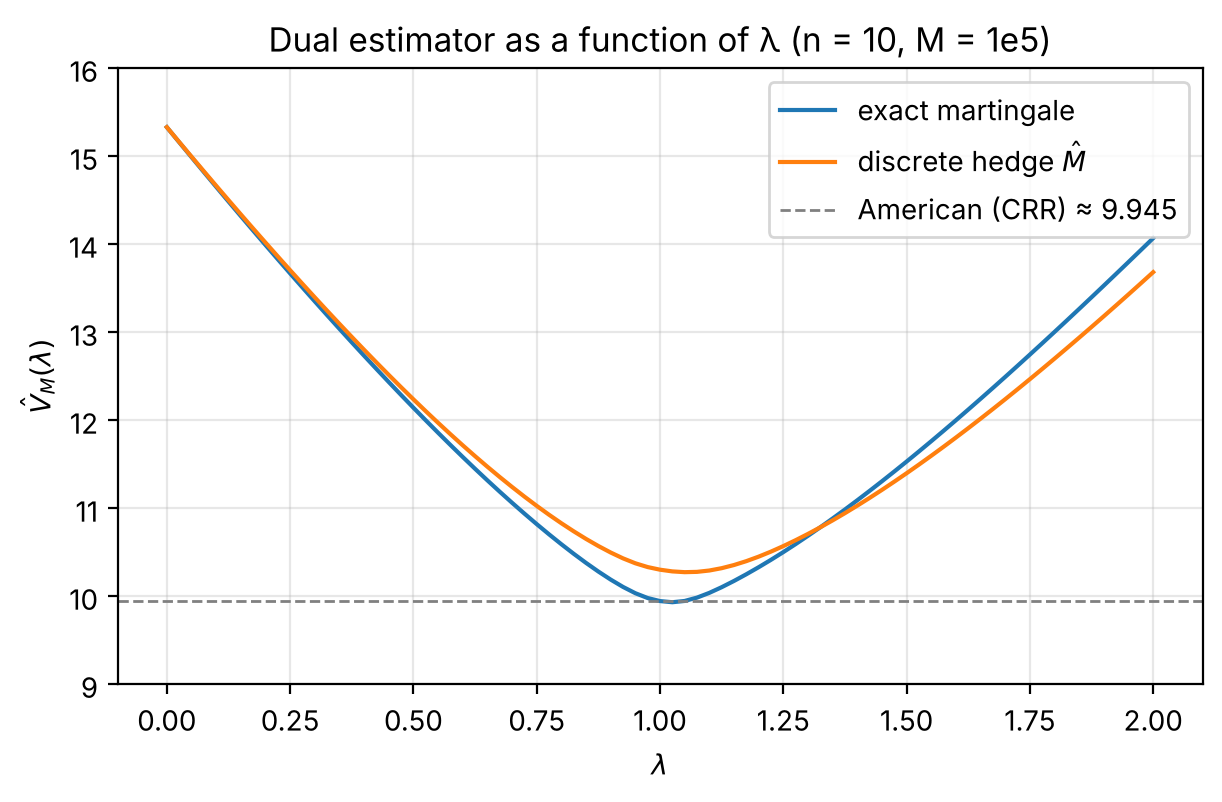

In [6]:
lams = np.linspace(0.0, 2.0, 81)
vals_ex = [dual_estimator(l, Z, Mex) for l in lams]
vals_h = [dual_estimator(l, Z, Mh) for l in lams]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lams, vals_ex, label="exact martingale")
ax.plot(lams, vals_h, label=r"discrete hedge $\hat M$")
ax.axhline(9.945, color="grey", ls="--", lw=1, label="American (CRR) ≈ 9.945")
ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"$\hat V_M(\lambda)$")
ax.set_title("Dual estimator as a function of λ (n = 10, M = 1e5)")
ax.set_ylim(9, 16); ax.legend(); ax.grid(alpha=0.3)
plt.show()

The curve is convex with a clear minimum near $\lambda\approx 1$. This makes sense: at $\lambda=1$, $M$ is exactly the martingale that hedges the European put, and the American put is the European put plus an early exercise premium.

## 5. Reference prices from a binomial tree

The dual estimator with $n$ dates bounds the price of the **Bermudan** option with $n$ dates, not the American price directly. To assess the bound, we compute the Bermudan price on a fine CRR tree where exercise is only allowed at the dates $t_k$, as well as the American price (exercise at every step).

In [ ]:
def crr_put(N, exercise_every=1):
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt)); d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d); disc = np.exp(-r * dt)
    j = np.arange(N + 1)
    V = payoff(S0 * u**(N - 2 * j))
    for i in range(N - 1, -1, -1):
        V = disc * (p * V[:-1] + (1 - p) * V[1:])
        if i % exercise_every == 0:
            V = np.maximum(V, payoff(S0 * u**(i - 2 * np.arange(i + 1))))
    return V[0]


def bermudan_price(n, steps_per_date=None):
    m = steps_per_date or max(1, int(np.ceil(4000 / n)))
    return crr_put(n * m, exercise_every=m)


amer = 0.5 * (crr_put(8000) + crr_put(8001)) 
print(f"American (CRR)    : {amer:.4f}")
print(f"Bermudan n = 10   : {bermudan_price(10):.4f}")
print(f"European (CRR)    : {crr_put(8000, exercise_every=10**9):.4f}  vs BS {bs_put(0.0, np.array([S0]))[0][0]:.4f}")

American (CRR)    : 9.9452
Bermudan n = 10   : 9.9067
European (CRR)    : 9.6639  vs BS 9.6642


The tree matches the Black-Scholes European price to within a cent, which validates it. It gives an American price of about 9.945, used as the reference from now on.

## 6. Approximate martingale: the discrete hedging portfolio $\hat M$

We now replace $M$ by $\hat M_t = \sum_k \Delta_{t_k}(\tilde S_{t_{k+1}\wedge t}-\tilde S_{t_k\wedge t})\mathbf 1_{\{t_k\ge\tau_0\}}$. It only requires the European **delta**, not the price, which generalizes to settings where only a sensitivity is available. The downside: $\hat M - M$ is the discrete hedging error, of order $\sqrt{T/n}$ in $L^2$, which loosens the bound for small $n$.

In [8]:
t0 = time.time()
res_hat = dual_upper_bound(10, 100_000, "hat")
print(f"n = 10, M = 1e5, discrete hedge  ({time.time()-t0:.1f} s)")
print(f"  lambda*                     = {res_hat['lam']:.4f}")
print(f"  in-sample min               = {res_hat['in_sample']:.4f}")
print(f"  upper bound (out-of-sample) = {res_hat['upper']:.4f}  ± {1.96*res_hat['se']:.4f} (95% CI)")

n = 10, M = 1e5, discrete hedge  (0.4 s)
  lambda*                     = 1.0557
  in-sample min               = 10.2731
  upper bound (out-of-sample) = 10.2653  ± 0.0369 (95% CI)


## 7. Effect of the number of exercise dates $n$

For $n\in\{10,20,40,100,200\}$ and $M=10^5$, we compute the out-of-sample bound, $\lambda^*$ and the standard error for each martingale, and compare them with the Bermudan price at $n$ dates and the American price.

In [9]:
ns = [10, 20, 40, 100, 200]
rows = []
for n in ns:
    re_ = dual_upper_bound(n, 100_000, "exact", seed=SEED + n)
    rh_ = dual_upper_bound(n, 100_000, "hat", seed=SEED + n)
    rows.append((n, bermudan_price(n), re_, rh_))

print(f"{'n':>4} | {'Bermudan':>8} | {'exact':>8} {'CI95':>6} {'lam':>6} | {'discrete':>8} {'CI95':>6} {'lam':>6} | {'λ=0':>7}")
print("-" * 82)
for n, berm, re_, rh_ in rows:
    print(f"{n:4d} | {berm:8.4f} | {re_['upper']:8.4f} {1.96*re_['se']:6.4f} {re_['lam']:6.3f} | "
          f"{rh_['upper']:8.4f} {1.96*rh_['se']:6.4f} {rh_['lam']:6.3f} | {re_['no_mart']:7.3f}")
print(f"American price (CRR): {amer:.4f}")

   n | Bermudan |    exact   CI95    lam | discrete   CI95    lam |     λ=0
----------------------------------------------------------------------------------
  10 |   9.9067 |   9.9255 0.0331  1.024 |  10.2632 0.0371  1.056 |  15.300
  20 |   9.9253 |   9.9461 0.0263  1.029 |  10.2152 0.0291  1.050 |  16.363
  40 |   9.9349 |   9.9760 0.0211  1.032 |  10.1758 0.0230  1.043 |  17.164
 100 |   9.9408 |   9.9578 0.0165  1.033 |  10.0697 0.0175  1.041 |  17.796
 200 |   9.9428 |   9.9694 0.0136  1.034 |  10.0406 0.0142  1.039 |  18.199
American price (CRR): 9.9452


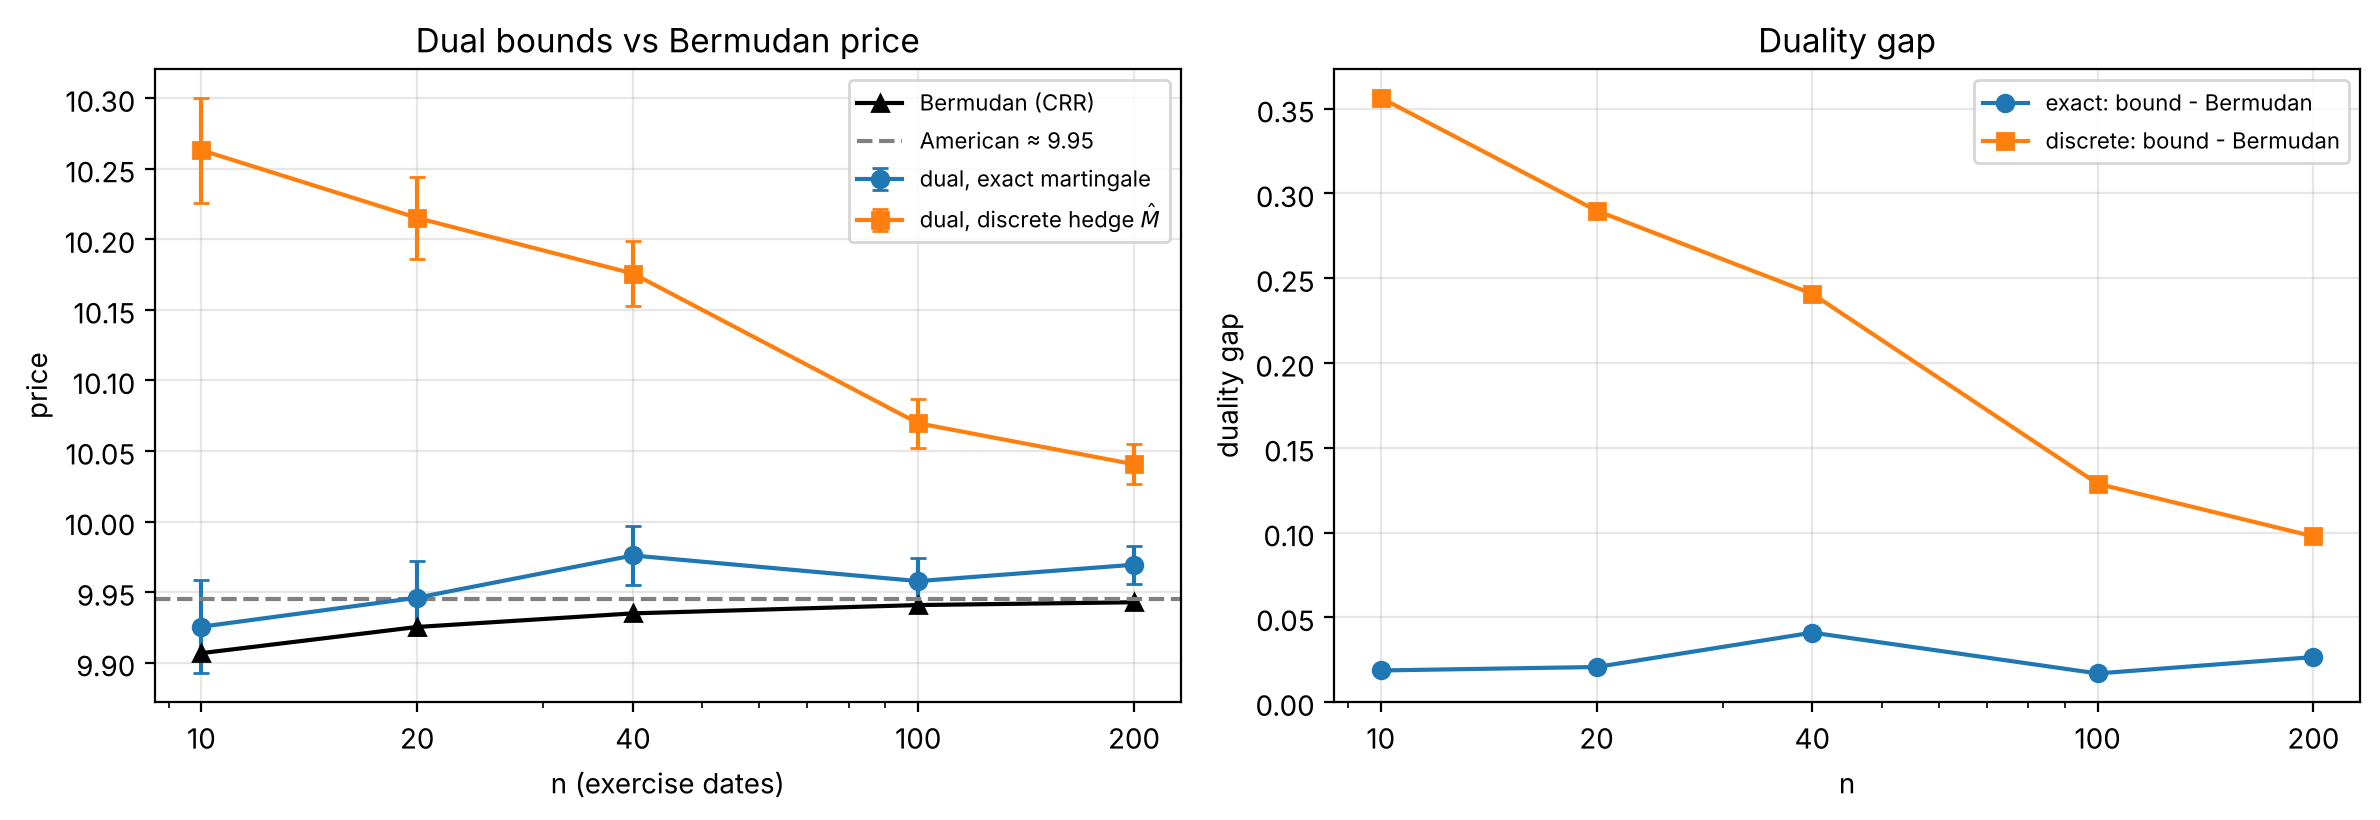

In [10]:
berm = np.array([b for _, b, _, _ in rows])
ue = np.array([e["upper"] for *_, e, _ in rows]); se_e = np.array([e["se"] for *_, e, _ in rows])
uh = np.array([h["upper"] for *_, h in rows]);   se_h = np.array([h["se"] for *_, h in rows])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.errorbar(ns, ue, yerr=1.96 * se_e, marker="o", capsize=3, label="dual, exact martingale")
ax.errorbar(ns, uh, yerr=1.96 * se_h, marker="s", capsize=3, label=r"dual, discrete hedge $\hat M$")
ax.plot(ns, berm, "k^-", label="Bermudan (CRR)")
ax.axhline(amer, color="grey", ls="--", label=f"American ≈ {amer:.2f}")
ax.set_xscale("log"); ax.set_xticks(ns); ax.set_xticklabels(ns)
ax.set_xlabel("n (exercise dates)"); ax.set_ylabel("price")
ax.set_title("Dual bounds vs Bermudan price"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(ns, ue - berm, "o-", label="exact: bound - Bermudan")
ax.plot(ns, uh - berm, "s-", label="discrete: bound - Bermudan")
ax.set_xscale("log"); ax.set_xticks(ns); ax.set_xticklabels(ns)
ax.set_xlabel("n"); ax.set_ylabel("duality gap")
ax.set_title("Duality gap"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The **Bermudan price** increases with $n$ towards the American price, since more exercise dates means more rights for the holder. The dual bounds sit above the Bermudan price at $n$ dates, and the gap between the two is the **duality gap**: how far $\lambda M$ is from the optimal Doob-Meyer martingale.

**Exact martingale.** As $n$ grows, the max runs over more dates, so the bound increases and converges to the continuous-time bound $\inf_\lambda\mathbb E[\sup_{t\le T}(Z_t-\lambda M_t)]$. It does not converge to the American price exactly, since the family $\{\lambda M\}$ does not contain the optimal martingale. The remaining gap is 2 to 4 cents here, under 0.5% of the price: a single parameter already gives a very tight bound. The bound is not perfectly monotone in $n$ in the table, but the differences between $n=40$, $100$ and $200$ are within the confidence intervals ($\pm 0.02$), so a larger $M$ would be needed to separate them.

**Discrete hedge $\hat M$.** The bound is always valid, but for small $n$ the hedging error $\hat M - M$ adds noise, which widens both the duality gap and the variance. As $n$ grows, $\hat M\to M$ and the two bounds meet.

**Variance.** The standard error with a good martingale is much smaller than with $\lambda=0$: subtracting the hedging martingale removes most of the randomness of the payoff. For the optimal martingale, $\max_t(Z_t - M^*_t)$ is **constant** and equal to $U_0$, so the estimator has zero variance.

**Cost.** Memory and time scale as $O(Mn)$. For $n=200$ and $M=10^5$, each sample takes a few seconds, dominated by the evaluation of $N(d_1)$.

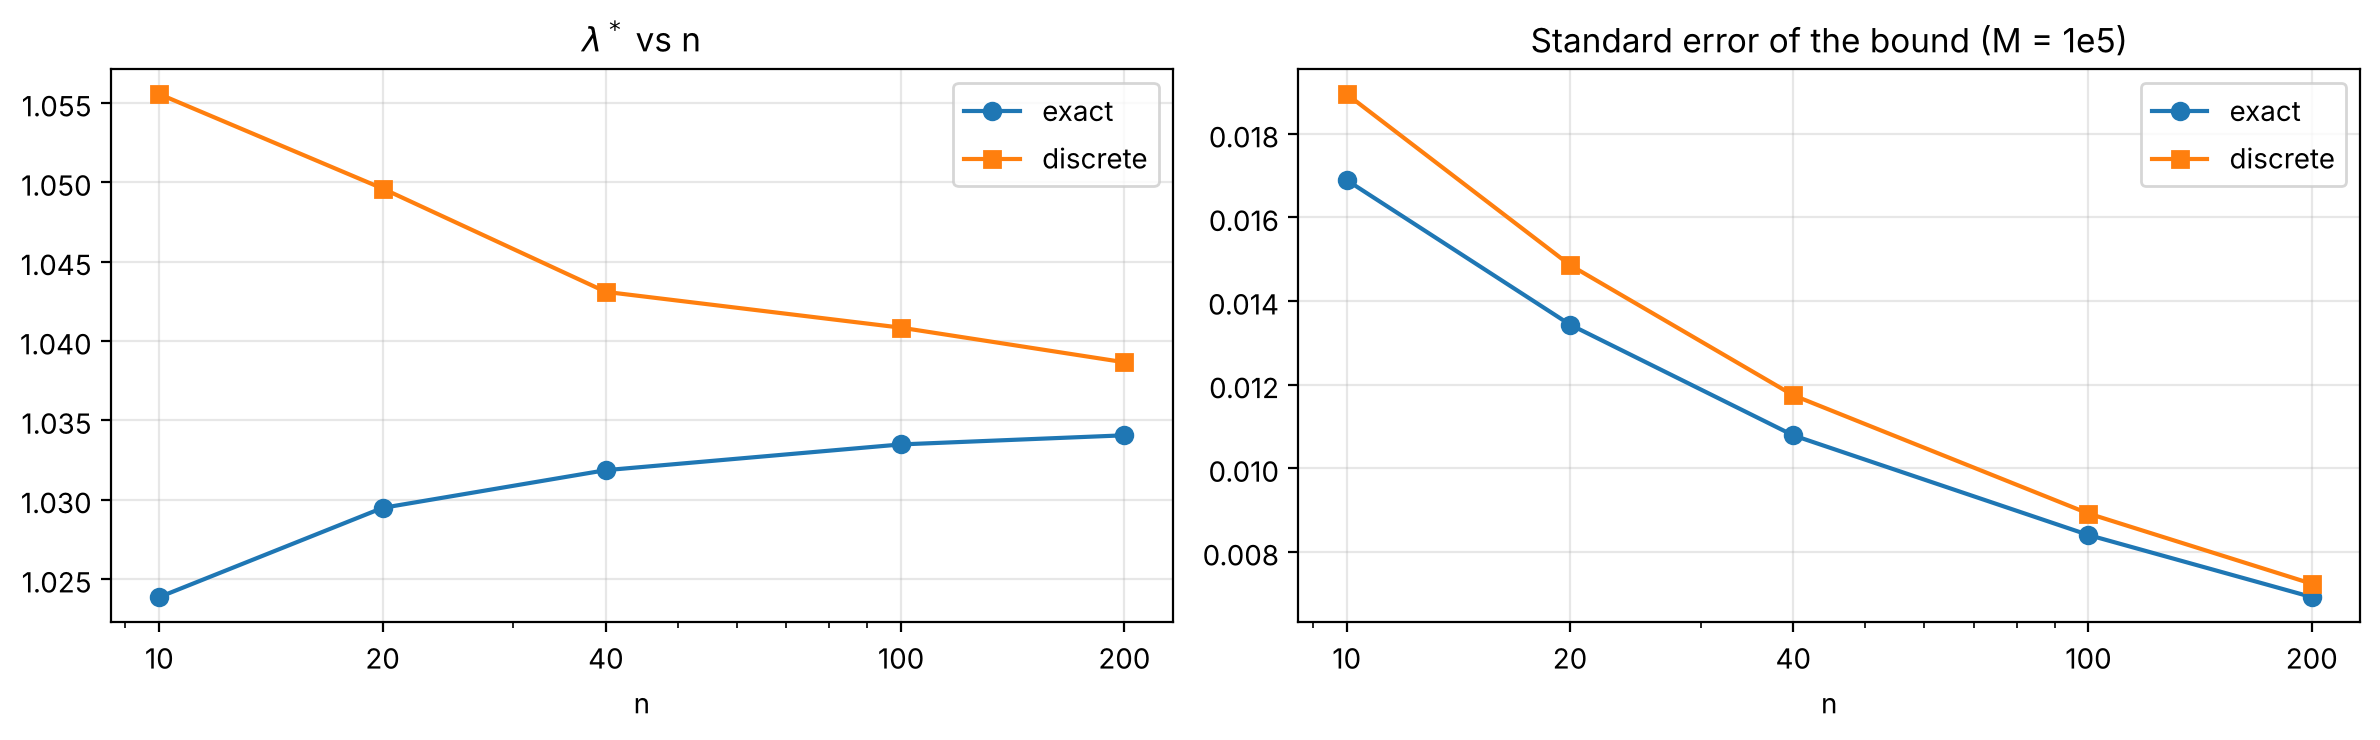

In [11]:
lam_e = [e["lam"] for *_, e, _ in rows]; lam_h = [h["lam"] for *_, h in rows]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(ns, lam_e, "o-", label="exact"); axes[0].plot(ns, lam_h, "s-", label="discrete")
axes[0].set_xscale("log"); axes[0].set_xticks(ns); axes[0].set_xticklabels(ns)
axes[0].set_title(r"$\lambda^*$ vs n"); axes[0].set_xlabel("n"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ns, se_e, "o-", label="exact"); axes[1].plot(ns, se_h, "s-", label="discrete")
axes[1].set_xscale("log"); axes[1].set_xticks(ns); axes[1].set_xticklabels(ns)
axes[1].set_title("Standard error of the bound (M = 1e5)"); axes[1].set_xlabel("n"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()